# 08 — Fidelity Evaluation: TVAE vs CTGAN vs TabDDPM

**Capstone:** Comparative Evaluation of Diffusion, GAN, and VAE Models for Synthetic Clinical Tabular Data Generation

**Goal:** Compare *saved* synthetic datasets against the **real training partition** on marginal distributions, minority-class prevalence, category coverage and numerical dependencies. This notebook **does not train or sample** any model, and it **does not use the held-out test partition**.

Models: TVAE (50-epoch baseline), TVAE (300 epochs), CTGAN (300 epochs), and TabDDPM-inspired joint diffusion (100 epochs). Epoch counts differ; these results compare generated data quality, **not equal training budgets**.

**Outputs:** `results/fidelity/*.csv` and `results/fidelity/*.png`. The held-out patient-disjoint test data is reserved for downstream TSTR utility evaluation.

## 1. Imports and project paths

Use the DGX `.venv` Python kernel. The notebook works when opened from the `notebooks/` directory or the project root. It reads the same processed data and preprocessing metadata used in the training notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, wasserstein_distance
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "data/processed/train_semantic.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/processed/train_semantic.csv").exists(), (
    f"Could not find project root from {Path.cwd()}"
)
OUT_DIR = ROOT / "results/fidelity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = ROOT / "data/processed/train_semantic.csv"
META_PATH = ROOT / "data/processed/preprocessing_metadata.json"
MODEL_PATHS = {
    "TVAE 50": ROOT / "data/synthetic/tvae_50ep.csv",
    "TVAE 300": ROOT / "data/synthetic/tvae_300ep.csv",
    "CTGAN 300": ROOT / "data/synthetic/ctgan_300ep.csv",
    "TabDDPM 100": ROOT / "data/synthetic/tabddpm_joint_100ep.csv",
}

print("Project:", ROOT)
print("Output directory:", OUT_DIR.relative_to(ROOT))

Project: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation
Output directory: results/fidelity


## 2. Load data and check schemas

The preprocessing metadata defines **8 true numerical features**. Hospital administrative codes such as `admission_type_id`, `discharge_disposition_id`, and `admission_source_id` are **categorical**, even though pandas loads their values as integers. The outcome `readmitted_30` is evaluated as a binary category, not a continuous numeric feature.

All synthetic files must have the same 45 columns and the same number of rows as the real training data. A missing file stops the evaluation rather than silently omitting a model.

In [2]:
with open(META_PATH, "r", encoding="utf-8") as f:
    meta = json.load(f)
NUM_COLS = list(meta["numerical_feature_columns"])
CAT_COLS = list(meta["categorical_feature_columns"])
TARGET = meta["target_column"]
assert TARGET == "readmitted_30"
assert len(NUM_COLS) == 8 and len(CAT_COLS) == 36

real = pd.read_csv(TRAIN_PATH)
assert real.shape == (79567, 45), f"Unexpected training data: {real.shape}"
expected_cols = list(real.columns)
assert set(NUM_COLS + CAT_COLS + [TARGET]) == set(expected_cols), "Metadata/schema mismatch"

missing_files = [str(path.relative_to(ROOT)) for path in MODEL_PATHS.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing synthetic files on DGX:\n" + "\n".join(missing_files))

synthetic = {name: pd.read_csv(path) for name, path in MODEL_PATHS.items()}
for name, df in synthetic.items():
    assert df.shape == real.shape, f"{name}: expected {real.shape}, got {df.shape}"
    assert set(df.columns) == set(expected_cols), f"{name}: mismatched columns"
    synthetic[name] = df[expected_cols].copy()

summary_shapes = pd.DataFrame(
    [{"dataset": "Real training", "rows": len(real), "columns": real.shape[1]}]
    + [{"dataset": name, "rows": len(df), "columns": df.shape[1]} for name, df in synthetic.items()]
)
display(summary_shapes)
print("Numerical columns:", NUM_COLS)
print("Categorical feature count:", len(CAT_COLS), "+ 1 binary target")

,dataset,rows,columns
0,Real training,79567,45
1,TVAE 50,79567,45
2,TVAE 300,79567,45
3,CTGAN 300,79567,45
4,TabDDPM 100,79567,45


Numerical columns: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical feature count: 36 + 1 binary target


## 3. Minority-class preservation

For `readmitted_30 = 1`, compare the number of positive records and the positive-rate gap in **percentage points**. Smaller absolute gap is better, but matching prevalence alone does not imply clinical fidelity or downstream utility.

,dataset,positive_count,positive_rate_pct,rate_gap_pp,abs_rate_gap_pp
0,Real training,9070,11.399,0.000,0.000
1,TVAE 50,0,0.000,-11.399,11.399
2,TVAE 300,34,0.043,-11.356,11.356
3,CTGAN 300,3279,4.121,-7.278,7.278
4,TabDDPM 100,8407,10.566,-0.833,0.833


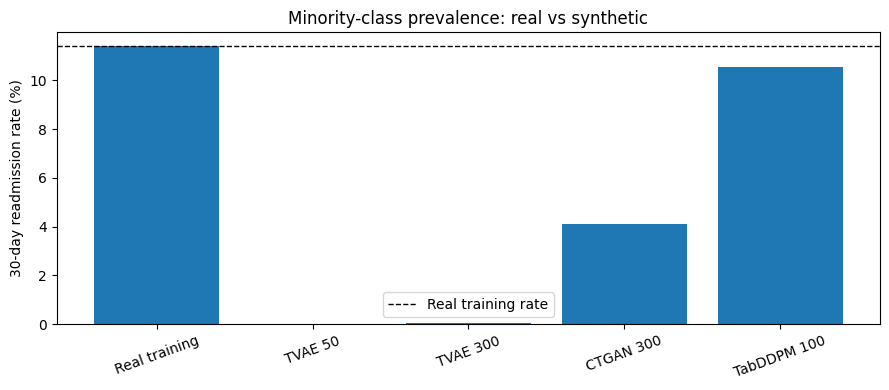

In [3]:
def positive_stats(df):
    y = pd.to_numeric(df[TARGET], errors="coerce")
    assert y.notna().all() and set(y.unique()).issubset({0, 1}), "Invalid target labels"
    return int(y.eq(1).sum()), float(y.eq(1).mean() * 100)

real_pos, real_pct = positive_stats(real)
rows = [{
    "dataset": "Real training", "positive_count": real_pos,
    "positive_rate_pct": real_pct, "rate_gap_pp": 0.0, "abs_rate_gap_pp": 0.0
}]
for name, df in synthetic.items():
    count, pct = positive_stats(df)
    rows.append({"dataset": name, "positive_count": count,
                 "positive_rate_pct": pct, "rate_gap_pp": pct - real_pct,
                 "abs_rate_gap_pp": abs(pct - real_pct)})
prevalence = pd.DataFrame(rows)
prevalence.to_csv(OUT_DIR / "readmission_prevalence.csv", index=False)
display(prevalence.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(prevalence["dataset"], prevalence["positive_rate_pct"])
ax.axhline(real_pct, color="black", linestyle="--", linewidth=1, label="Real training rate")
ax.set_ylabel("30-day readmission rate (%)")
ax.set_title("Minority-class prevalence: real vs synthetic")
ax.tick_params(axis="x", rotation=20)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "readmission_prevalence.png", dpi=160)
plt.show()

## 4. Numerical marginal fidelity

For each of the 8 numerical features, calculate:

- **Two-sample KS statistic** (0 is identical empirical CDFs; lower is better).
- **Normalized Wasserstein distance** (absolute Wasserstein distance divided by the real training IQR; if IQR = 0, use real standard deviation, then 1 as last resort). Lower is better.
- Real and synthetic means, plus mean difference.

These are descriptive distribution distances, not model-training losses or hypothesis-test conclusions. Scaling uses the **real training data only**.

,ks_statistic,normalized_wasserstein
model,,
TVAE 50,0.1805,0.2587
TVAE 300,0.1387,0.2092
CTGAN 300,0.1720,0.2964
TabDDPM 100,0.0378,0.0505


model,CTGAN 300,TVAE 300,TVAE 50,TabDDPM 100
column,,,,
num_lab_procedures,0.1955,0.0665,0.0937,0.0296
num_medications,0.2037,0.0867,0.1114,0.0426
num_procedures,0.1814,0.1639,0.2169,0.0700
number_diagnoses,0.1147,0.0334,0.3018,0.0777
number_emergency,0.0447,0.1106,0.1121,0.0098
number_inpatient,0.3352,0.3129,0.3284,0.0080
number_outpatient,0.1146,0.1555,0.1618,0.0209
time_in_hospital,0.1864,0.1800,0.1175,0.0439


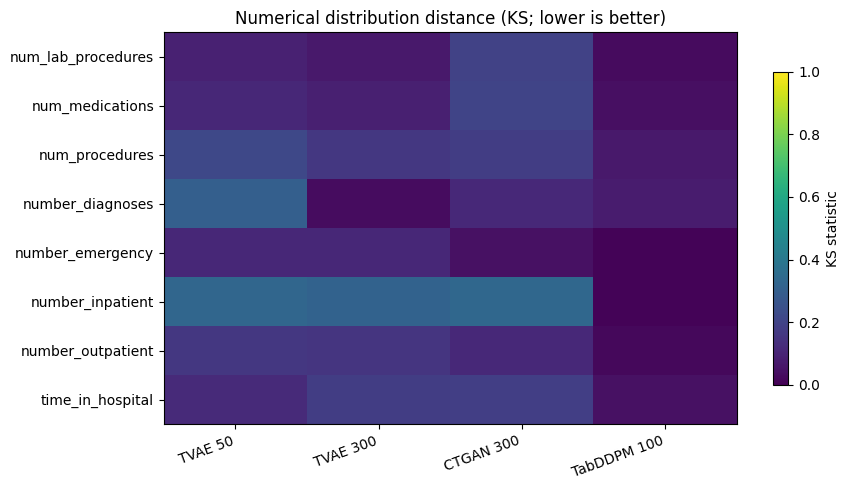

In [4]:
num_rows = []
for name, df in synthetic.items():
    for col in NUM_COLS:
        a = pd.to_numeric(real[col], errors="coerce").dropna().to_numpy(dtype=float)
        b = pd.to_numeric(df[col], errors="coerce").dropna().to_numpy(dtype=float)
        a, b = a[np.isfinite(a)], b[np.isfinite(b)]
        if len(a) == 0 or len(b) == 0:
            ks, wd, m_real, m_synth = np.nan, np.nan, np.nan, np.nan
        else:
            ks = float(ks_2samp(a, b, method="asymp").statistic)
            iqr = float(np.subtract(*np.percentile(a, [75, 25])))
            scale = iqr if iqr > 0 else float(np.std(a))
            scale = scale if scale > 0 else 1.0
            wd = float(wasserstein_distance(a, b) / scale)
            m_real, m_synth = float(np.mean(a)), float(np.mean(b))
        num_rows.append({"model": name, "column": col, "ks_statistic": ks,
                         "normalized_wasserstein": wd, "real_mean": m_real,
                         "synthetic_mean": m_synth,
                         "mean_difference": m_synth - m_real})
num_metrics = pd.DataFrame(num_rows)
num_metrics.to_csv(OUT_DIR / "numeric_column_metrics.csv", index=False)
display(num_metrics.groupby("model", sort=False)[["ks_statistic", "normalized_wasserstein"]].mean().round(4))
display(num_metrics.pivot(index="column", columns="model", values="ks_statistic").round(4))

heat = num_metrics.pivot(index="column", columns="model", values="ks_statistic").reindex(columns=list(synthetic))
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heat.values, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(heat.columns)), heat.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_title("Numerical distribution distance (KS; lower is better)")
fig.colorbar(im, ax=ax, shrink=0.8, label="KS statistic")
fig.tight_layout()
fig.savefig(OUT_DIR / "numeric_ks_heatmap.png", dpi=160)
plt.show()

## 5. Categorical marginal fidelity

Compare the **36 categorical features**, keeping the target separate:

- **Total variation distance (TVD):** half the sum of absolute probability differences over the union of categories. Range 0–1; lower is better.
- **Real-category coverage:** fraction of categories observed in real training data also present in generated data. Higher is better.
- **Novel-category row share:** percentage of synthetic values outside the training categories; lower is better (0 can still occur even when frequency fidelity is poor).

The literal `Missing` and `Not_recorded` values are meaningful categories in the preprocessed data and are **not discarded**.

,tvd,real_category_coverage,novel_category_row_share
model,,,
TVAE 50,0.0902,0.5365,0.0
TVAE 300,0.0720,0.6667,0.0
CTGAN 300,0.0846,1.0000,0.0
TabDDPM 100,0.0143,0.9193,0.0


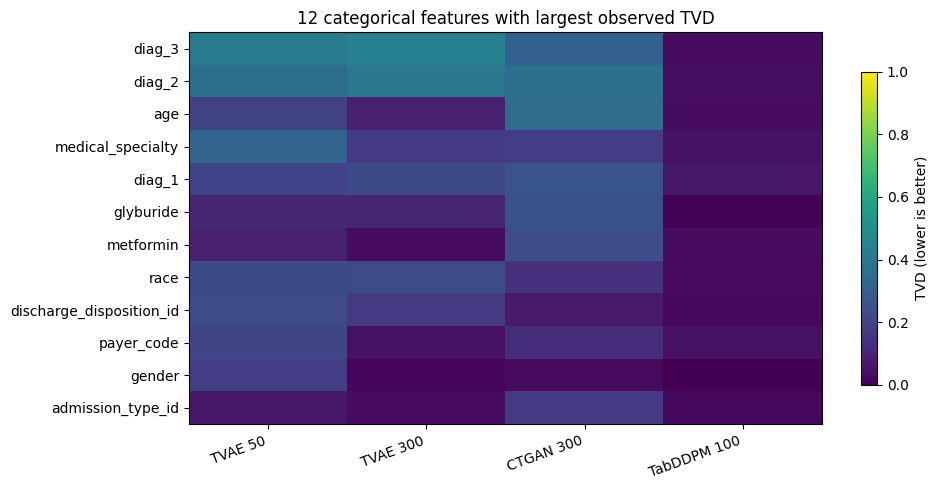

In [5]:
def as_categories(series):
    return series.astype("string").fillna("<NA>").astype(str)

def cat_distances(a_series, b_series):
    a = as_categories(a_series)
    b = as_categories(b_series)
    pa = a.value_counts(normalize=True)
    pb = b.value_counts(normalize=True)
    labels = pa.index.union(pb.index)
    tvd = float(0.5 * (pa.reindex(labels, fill_value=0) - pb.reindex(labels, fill_value=0)).abs().sum())
    coverage = len(pa.index.intersection(pb.index)) / len(pa.index) if len(pa) else np.nan
    novel_share = float((~b.isin(pa.index)).mean())
    return tvd, coverage, novel_share, len(pa), len(pb)

cat_rows = []
for name, df in synthetic.items():
    for col in CAT_COLS:
        tvd, coverage, novel, n_real, n_synth = cat_distances(real[col], df[col])
        cat_rows.append({"model": name, "column": col, "tvd": tvd,
                         "real_category_coverage": coverage,
                         "novel_category_row_share": novel,
                         "real_categories": n_real, "synthetic_categories": n_synth})
cat_metrics = pd.DataFrame(cat_rows)
cat_metrics.to_csv(OUT_DIR / "categorical_column_metrics.csv", index=False)
display(cat_metrics.groupby("model", sort=False)[["tvd", "real_category_coverage", "novel_category_row_share"]].mean().round(4))

most_different = cat_metrics.groupby("column")["tvd"].max().nlargest(12).index
chart = cat_metrics[cat_metrics["column"].isin(most_different)].pivot(index="column", columns="model", values="tvd").reindex(index=most_different, columns=list(synthetic))
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(chart.values, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(chart.columns)), chart.columns, rotation=20, ha="right")
ax.set_yticks(range(len(chart.index)), chart.index)
ax.set_title("12 categorical features with largest observed TVD")
fig.colorbar(im, ax=ax, shrink=0.8, label="TVD (lower is better)")
fig.tight_layout()
fig.savefig(OUT_DIR / "categorical_tvd_heatmap.png", dpi=160)
plt.show()

## 6. Numerical dependence: Spearman correlation differences

Using the same 8 numerical features, compare each model's pairwise Spearman correlations with those from real training data. The score is the **mean absolute difference** across finite off-diagonal pairs. Lower is better. This assesses only a subset of multivariate structure; it does not capture categorical–numerical or higher-order interactions.

In [6]:
real_corr = real[NUM_COLS].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
corr_rows = []
mask_upper = np.triu(np.ones((len(NUM_COLS), len(NUM_COLS)), dtype=bool), k=1)
for name, df in synthetic.items():
    synth_corr = df[NUM_COLS].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
    differences = (synth_corr - real_corr).abs().to_numpy()
    vals = differences[mask_upper]
    finite = vals[np.isfinite(vals)]
    corr_rows.append({"model": name,
                      "mean_abs_spearman_gap": float(finite.mean()) if len(finite) else np.nan,
                      "valid_pairs": len(finite), "possible_pairs": int(mask_upper.sum())})
corr_metrics = pd.DataFrame(corr_rows)
corr_metrics.to_csv(OUT_DIR / "correlation_gap.csv", index=False)
display(corr_metrics.round(4))

,model,mean_abs_spearman_gap,valid_pairs,possible_pairs
0,TVAE 50,0.0969,28,28
1,TVAE 300,0.0478,28,28
2,CTGAN 300,0.1104,28,28
3,TabDDPM 100,0.0188,28,28


## 7. Stratified descriptive check for positive readmissions

Compare prior-visit averages **among positive readmission cases only**, where positive cases exist. If TVAE 50 generates no positive cases, its subgroup means are undefined and shown as `NaN`. Interpret TVAE 300's subgroup estimates cautiously because it generated only a few dozen positive cases.

In [7]:
VISIT_COLS = ["number_outpatient", "number_emergency", "number_inpatient"]
conditional_rows = []
for name, df in [("Real training", real)] + list(synthetic.items()):
    pos = df[pd.to_numeric(df[TARGET], errors="coerce").eq(1)]
    record = {"dataset": name, "positive_n": len(pos)}
    for col in VISIT_COLS:
        record[f"positive_mean_{col}"] = float(pd.to_numeric(pos[col], errors="coerce").mean()) if len(pos) else np.nan
    conditional_rows.append(record)
conditional = pd.DataFrame(conditional_rows)
conditional.to_csv(OUT_DIR / "conditional_positive_means.csv", index=False)
display(conditional.round(3))

,dataset,positive_n,positive_mean_number_outpatient,positive_mean_number_emergency,positive_mean_number_inpatient
0,Real training,9070,0.429,0.358,1.212
1,TVAE 50,0,NaN,NaN,NaN
2,TVAE 300,34,0.176,1.000,3.794
3,CTGAN 300,3279,0.122,0.056,1.273
4,TabDDPM 100,8407,0.413,0.212,1.194


## 8. Consolidated summary and save results

These separate metrics evaluate different aspects of fidelity; **do not interpret a single score as overall superiority**. In particular, preservation of readmission prevalence is not enough to establish validity, safety, privacy, fairness or predictive utility. Next phases: **TSTR utility** using the patient-disjoint test set, then **privacy risk assessment**.

In [8]:
num_agg = num_metrics.groupby("model")[["ks_statistic", "normalized_wasserstein"]].mean()
cat_agg = cat_metrics.groupby("model")[["tvd", "real_category_coverage", "novel_category_row_share"]].mean()
prev_agg = prevalence[prevalence["dataset"] != "Real training"].set_index("dataset")[["positive_rate_pct", "abs_rate_gap_pp"]]
cor_agg = corr_metrics.set_index("model")[["mean_abs_spearman_gap"]]
summary = (prev_agg.rename_axis("model")
           .join(num_agg)
           .join(cat_agg)
           .join(cor_agg)
           .reindex(list(synthetic)))
summary.to_csv(OUT_DIR / "model_fidelity_summary.csv")
display(summary.round(4))

print("Saved fidelity tables and figures in:", OUT_DIR)
print("Training and model files have NOT been modified.")
print("Next: 09_utility_tstr.ipynb — use held-out test data only for final predictive evaluation.")

,positive_rate_pct,abs_rate_gap_pp,ks_statistic,normalized_wasserstein,tvd,real_category_coverage,novel_category_row_share,mean_abs_spearman_gap
model,,,,,,,,
TVAE 50,0.0000,11.3992,0.1805,0.2587,0.0902,0.5365,0.0,0.0969
TVAE 300,0.0427,11.3565,0.1387,0.2092,0.0720,0.6667,0.0,0.0478
CTGAN 300,4.1211,7.2781,0.1720,0.2964,0.0846,1.0000,0.0,0.1104
TabDDPM 100,10.5659,0.8333,0.0378,0.0505,0.0143,0.9193,0.0,0.0188


Saved fidelity tables and figures in: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/fidelity
Training and model files have NOT been modified.
Next: 09_utility_tstr.ipynb — use held-out test data only for final predictive evaluation.


## Notes for the capstone report

- The synthetic and real-train datasets contain the same number of rows, but that **does not** imply equivalent quality.
- TVAE 50 and TVAE 300 are separate baseline/tuned experiments. CTGAN 300 and TabDDPM 100 have different training budgets.
- The TabDDPM run in this project is a **TabDDPM-inspired joint Gaussian–categorical diffusion implementation**, not an exact reproduction of the official code.
- This notebook reports marginal and limited dependency fidelity, not TSTR utility, privacy protection, memorization risk, fairness or downstream clinical usefulness.
- No inference about individual patients should be drawn from these statistics.